In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import kaggle
from scipy.stats import randint
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token


In [2]:
%env KAGGLE_API_TOKEN=KGAT_ad0cfeb24599b0621d0eec44ad7ddd80
kaggle.api.authenticate()
kaggle.api.dataset_download_files('yasserh/titanic-dataset', path='.', unzip=True)

env: KAGGLE_API_TOKEN=KGAT_ad0cfeb24599b0621d0eec44ad7ddd80
Dataset URL: https://www.kaggle.com/datasets/yasserh/titanic-dataset


In [3]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5
N_JOBS = -1
MODEL_N_JOBS = 1
TOP_N = 10

DATA_PATH = "Titanic-Dataset.csv"
TARGET = "Survived"
DROP_COLUMNS = ["PassengerId", "Survived", "Name", "Ticket", "Cabin"]
NUM_FEATURES = ["Age", "Fare", "SibSp", "Parch"]
CAT_FEATURES = ["Pclass", "Sex", "Embarked"]

SCORING_MAIN = "f1"
SCORING_ALL = {
    "f1": "f1",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
}

BASELINE_NAME = "Baseline (ЛР2)"
GRID_NAME = "Grid Search"
RANDOM_NAME = "Random Search"

BASELINE_PARAMS = {
    "n_estimators": 300,
    "max_depth": None,
    "min_samples_leaf": 2,
    "max_features": "sqrt",
    "random_state": RANDOM_STATE,
    "n_jobs": MODEL_N_JOBS,
}

PARAM_GRID = {
    "model__n_estimators": [100, 300, 500],
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_leaf": [1, 2, 4],
}

PARAM_DISTRIBUTIONS = {
    "model__n_estimators": randint(100, 600),
    "model__max_depth": [3, 4, 5, 6, 8, 10, 12, None],
    "model__min_samples_leaf": randint(1, 10),
    "model__max_features": ["sqrt", "log2", 0.5, 1.0],
}

N_ITER = int(np.prod([len(values) for values in PARAM_GRID.values()]))
DEPTH_VALUES = [1, 2, 3, 4, 5, 6, 8, 10, 12, 16, None]
GRID_DEPTH_ORDER = [str(value) for value in PARAM_GRID["model__max_depth"]]
FOLD_LABELS = [f"Fold {i + 1}" for i in range(N_SPLITS)]

FIG_SIZE_SINGLE = (11, 5)
FIG_SIZE_GRID = (16, 10)

CV = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
sns.set_theme(style="whitegrid")

In [4]:
def build_preprocessor():
    return ColumnTransformer(
        [
            ("num", SimpleImputer(strategy="median"), NUM_FEATURES),
            (
                "cat",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                    ]
                ),
                CAT_FEATURES,
            ),
        ]
    )


def build_pipeline(**model_params):
    params = {**BASELINE_PARAMS, **model_params}
    return Pipeline(
        [
            ("prep", build_preprocessor()),
            ("model", RandomForestClassifier(**params)),
        ]
    )


def param_space_size(values):
    if isinstance(values, (list, tuple)):
        return len(values)
    low, high = values.args
    return int(high - low)


def space_size(space):
    return int(np.prod([param_space_size(values) for values in space.values()]))


def fit_search(searcher, X_tr, y_tr):
    start = time.perf_counter()
    searcher.fit(X_tr, y_tr)
    return searcher, time.perf_counter() - start


def search_summary(name, searcher, elapsed, space):
    n_combinations = len(searcher.cv_results_["params"])
    print(f"{name}: проверено комбинаций {n_combinations}, обучений {n_combinations * N_SPLITS}")
    print(f"Размер пространства поиска: {space_size(space)}")
    print(f"Время поиска: {elapsed:.1f} с")
    print(f"Лучший CV {SCORING_MAIN}: {searcher.best_score_:.4f}")
    print(f"Лучшие параметры: {searcher.best_params_}")
    return {
        "Стратегия": name,
        "Размер пространства": space_size(space),
        "Проверено комбинаций": n_combinations,
        "Обучений модели": n_combinations * N_SPLITS,
        "Время, с": round(elapsed, 1),
        "Лучший CV F1": round(searcher.best_score_, 4),
        "Лучшие параметры": str(searcher.best_params_),
    }


def search_results(searcher, top_n=TOP_N):
    table = pd.DataFrame(searcher.cv_results_)
    param_columns = [column for column in table.columns if column.startswith("param_")]
    columns = param_columns + [
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "mean_fit_time",
        "rank_test_score",
    ]
    return table[columns].sort_values("rank_test_score").head(top_n).round(4)


def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    cv_result = cross_validate(model, X_tr, y_tr, cv=CV, scoring=SCORING_ALL, n_jobs=N_JOBS)
    fitted = clone(model).fit(X_tr, y_tr)
    prediction = fitted.predict(X_te)
    row = {
        "Model": name,
        "CV F1": cv_result["test_f1"].mean(),
        "CV F1 std": cv_result["test_f1"].std(),
        "Test F1": f1_score(y_te, prediction),
        "Test Accuracy": accuracy_score(y_te, prediction),
        "Test Precision": precision_score(y_te, prediction),
        "Test Recall": recall_score(y_te, prediction),
    }
    return row, cv_result["test_f1"]

In [5]:
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=DROP_COLUMNS)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print(f"Датасет: {df.shape}, train: {X_train.shape}, test: {X_test.shape}")
print(f"Признаки: {list(X.columns)}")
print("Баланс классов в train:")
print(y_train.value_counts(normalize=True).round(3))

Датасет: (891, 12), train: (712, 7), test: (179, 7)
Признаки: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
Баланс классов в train:
Survived
0    0.624
1    0.376
Name: proportion, dtype: float64


In [6]:
print("Исходные гиперпараметры:", BASELINE_PARAMS)

baseline_cv = cross_validate(
    build_pipeline(), X_train, y_train, cv=CV, scoring=SCORING_ALL, n_jobs=N_JOBS
)

print(f"CV F1: {baseline_cv['test_f1'].mean():.4f} ± {baseline_cv['test_f1'].std():.4f}")
print(f"CV Accuracy: {baseline_cv['test_accuracy'].mean():.4f}")
print(f"CV Precision: {baseline_cv['test_precision'].mean():.4f}")
print(f"CV Recall: {baseline_cv['test_recall'].mean():.4f}")
print("F1 по фолдам:", np.round(baseline_cv["test_f1"], 4))

Исходные гиперпараметры: {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'random_state': 42, 'n_jobs': 1}
CV F1: 0.7335 ± 0.0506
CV Accuracy: 0.8146
CV Precision: 0.7981
CV Recall: 0.6829
F1 по фолдам: [0.6737 0.8269 0.7143 0.729  0.7234]


In [7]:
grid_search = GridSearchCV(
    build_pipeline(),
    PARAM_GRID,
    scoring=SCORING_MAIN,
    cv=CV,
    n_jobs=N_JOBS,
    refit=True,
    return_train_score=True,
)

grid_search, grid_time = fit_search(grid_search, X_train, y_train)
grid_summary = search_summary(GRID_NAME, grid_search, grid_time, PARAM_GRID)
display(search_results(grid_search))

Grid Search: проверено комбинаций 36, обучений 180
Размер пространства поиска: 36
Время поиска: 8.1 с
Лучший CV f1: 0.7397
Лучшие параметры: {'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}


,param_model__max_depth,param_model__min_samples_leaf,param_model__n_estimators,mean_train_score,mean_test_score,std_test_score,mean_fit_time,rank_test_score
10,5,1,300,0.7938,0.7397,0.0421,0.4277,1
22,8,2,300,0.8380,0.7379,0.0467,0.4169,2
11,5,1,500,0.7927,0.7372,0.0436,0.6219,3
15,5,4,100,0.7781,0.7360,0.0425,0.1343,4
3,3,2,100,0.7484,0.7360,0.0414,0.1342,5
23,8,2,500,0.8354,0.7357,0.0441,0.6922,6
20,8,1,500,0.8785,0.7355,0.0368,0.7103,7
19,8,1,300,0.8789,0.7355,0.0368,0.4312,7
12,5,2,100,0.7902,0.7348,0.0462,0.1354,9
32,None,2,500,0.8711,0.7336,0.0503,0.7079,10


In [8]:
random_search = RandomizedSearchCV(
    build_pipeline(),
    PARAM_DISTRIBUTIONS,
    n_iter=N_ITER,
    scoring=SCORING_MAIN,
    cv=CV,
    n_jobs=N_JOBS,
    random_state=RANDOM_STATE,
    refit=True,
    return_train_score=True,
)

random_search, random_time = fit_search(random_search, X_train, y_train)
random_summary = search_summary(RANDOM_NAME, random_search, random_time, PARAM_DISTRIBUTIONS)
display(search_results(random_search))

Random Search: проверено комбинаций 36, обучений 180
Размер пространства поиска: 144000
Время поиска: 9.5 с
Лучший CV f1: 0.7456
Лучшие параметры: {'model__max_depth': 8, 'model__max_features': 0.5, 'model__min_samples_leaf': 3, 'model__n_estimators': 314}


,param_model__max_depth,param_model__max_features,param_model__min_samples_leaf,param_model__n_estimators,mean_train_score,mean_test_score,std_test_score,mean_fit_time,rank_test_score
1,8,0.5,3,314,0.8413,0.7456,0.0422,0.4756,1
16,8,1.0,3,305,0.8616,0.7451,0.0537,0.6318,2
17,3,1.0,2,459,0.7682,0.7427,0.0510,0.6011,3
13,3,1.0,2,364,0.7685,0.7427,0.0510,0.5369,3
14,4,sqrt,2,439,0.7777,0.7415,0.0513,0.5876,5
12,3,0.5,2,487,0.7675,0.7375,0.0384,0.6166,6
6,None,1.0,5,260,0.8342,0.7375,0.0449,0.4795,7
3,6,1.0,8,230,0.7857,0.7370,0.0414,0.3702,8
33,6,log2,1,147,0.8194,0.7367,0.0359,0.2215,9
20,12,log2,2,301,0.8705,0.7364,0.0484,0.4213,10


In [9]:
search_comparison = pd.DataFrame([grid_summary, random_summary])
display(search_comparison)

print(f"Разница лучших CV F1 (Random - Grid): {random_search.best_score_ - grid_search.best_score_:+.4f}")
print(f"Разница времени (Random - Grid): {random_time - grid_time:+.1f} с")

,Стратегия,Размер пространства,Проверено комбинаций,Обучений модели,"Время, с",Лучший CV F1,Лучшие параметры
0,Grid Search,36,36,180,8.1,0.7397,"{'model__max_depth': 5, 'model__min_samples_le..."
1,Random Search,144000,36,180,9.5,0.7456,"{'model__max_depth': 8, 'model__max_features':..."


Разница лучших CV F1 (Random - Grid): +0.0059
Разница времени (Random - Grid): +1.4 с


,max_depth,Train F1,CV F1,CV F1 std
0,1,0.7017,0.6986,0.0463
1,2,0.7061,0.7029,0.0398
2,3,0.7471,0.7270,0.0404
3,4,0.7764,0.7385,0.0464
4,5,0.7901,0.7315,0.0386
5,6,0.8060,0.7342,0.0384
6,8,0.8380,0.7379,0.0467
7,10,0.8629,0.7307,0.0466
8,12,0.8705,0.7364,0.0484
9,16,0.8703,0.7365,0.0484


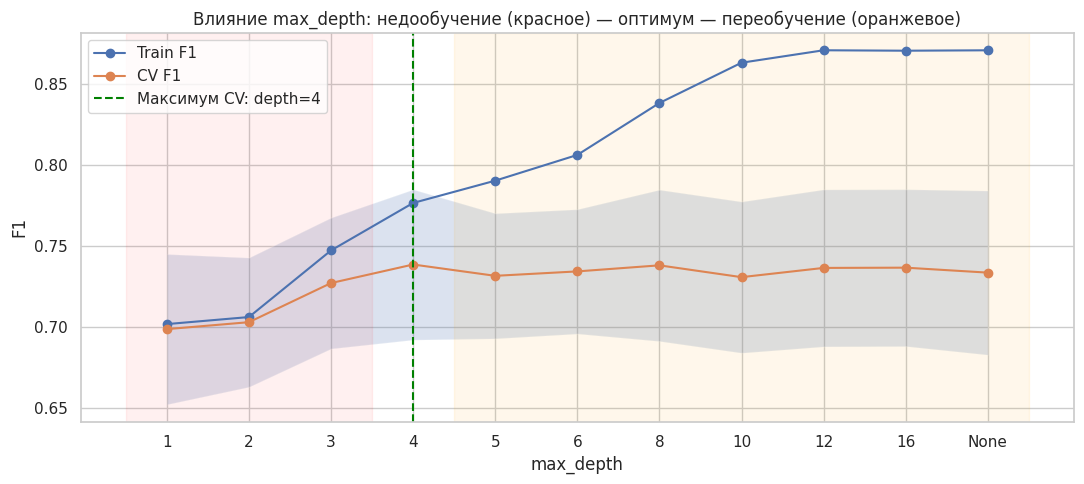

In [10]:
depth_rows = []
for depth in DEPTH_VALUES:
    result = cross_validate(
        build_pipeline(max_depth=depth),
        X_train,
        y_train,
        cv=CV,
        scoring=SCORING_MAIN,
        n_jobs=N_JOBS,
        return_train_score=True,
    )
    depth_rows.append(
        {
            "max_depth": str(depth),
            "Train F1": result["train_score"].mean(),
            "CV F1": result["test_score"].mean(),
            "CV F1 std": result["test_score"].std(),
        }
    )

depth_df = pd.DataFrame(depth_rows)
display(depth_df.round(4))

best_depth_index = int(depth_df["CV F1"].idxmax())
positions = np.arange(len(depth_df))
best_depth_label = depth_df.loc[best_depth_index, "max_depth"]

fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)
ax.plot(positions, depth_df["Train F1"], marker="o", label="Train F1")
ax.plot(positions, depth_df["CV F1"], marker="o", label="CV F1")
ax.fill_between(
    positions,
    depth_df["CV F1"] - depth_df["CV F1 std"],
    depth_df["CV F1"] + depth_df["CV F1 std"],
    alpha=0.2,
)
ax.axvspan(-0.5, best_depth_index - 0.5, color="red", alpha=0.06)
ax.axvspan(best_depth_index + 0.5, len(depth_df) - 0.5, color="orange", alpha=0.08)
ax.axvline(best_depth_index, color="green", linestyle="--", label=f"Максимум CV: depth={best_depth_label}")
ax.set_xticks(positions, depth_df["max_depth"])
ax.set_xlabel("max_depth")
ax.set_ylabel("F1")
ax.set_title("Влияние max_depth: недообучение (красное) — оптимум — переобучение (оранжевое)")
ax.legend()
plt.tight_layout()
plt.show()

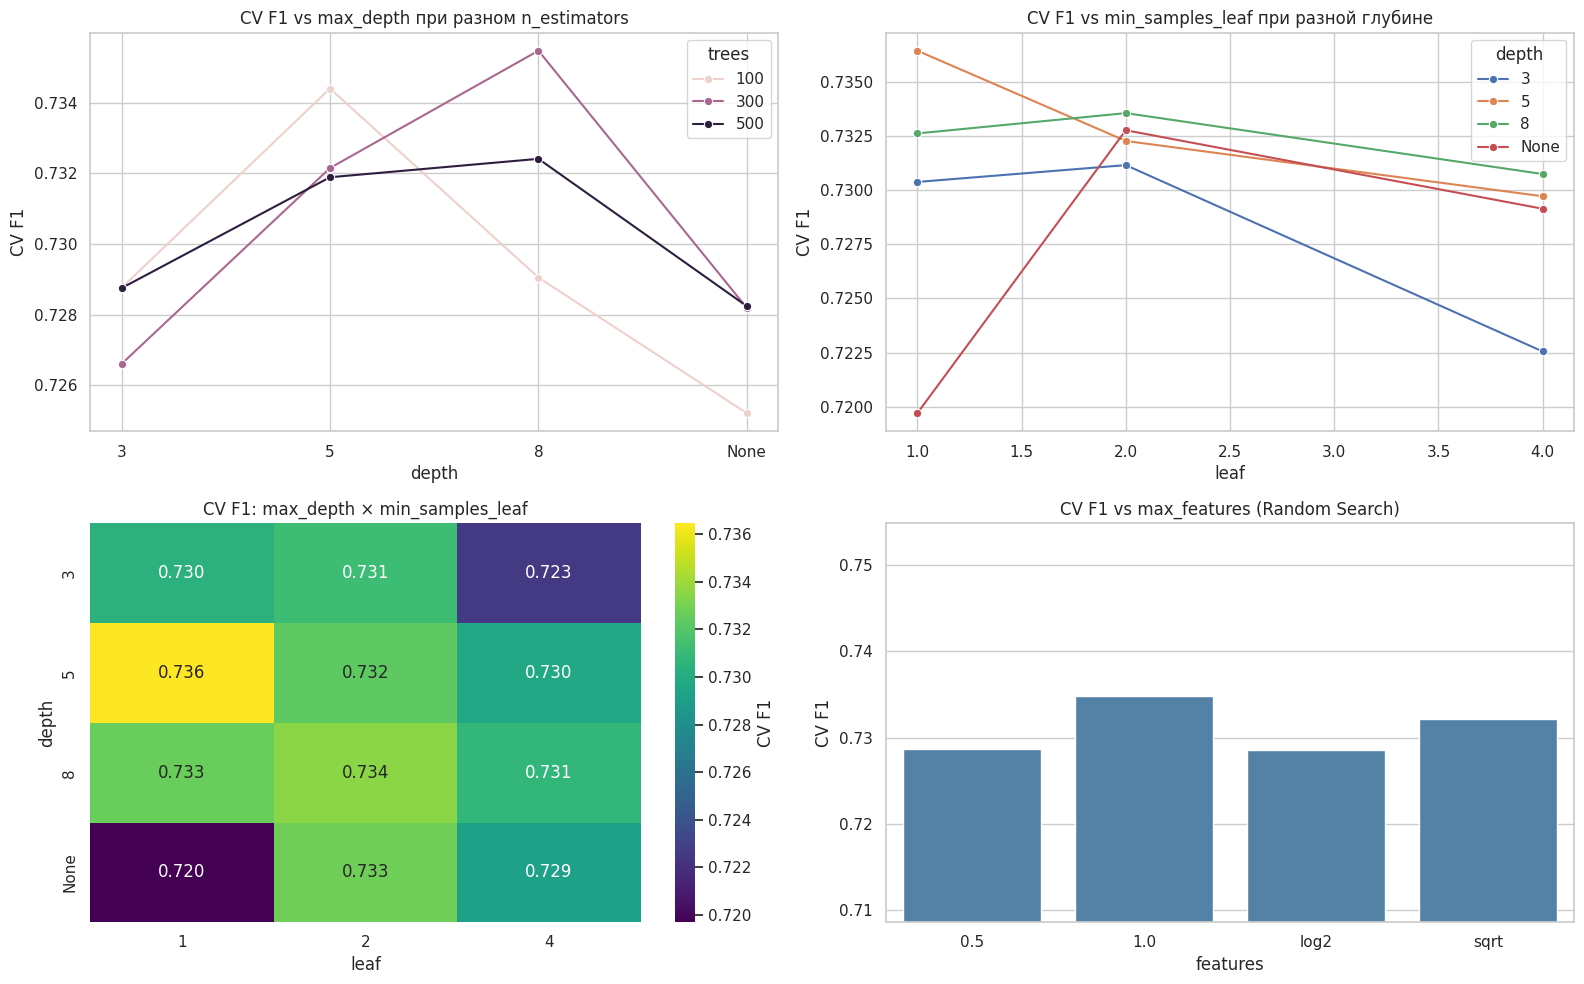

In [14]:
grid_results = pd.DataFrame(grid_search.cv_results_)
grid_results["depth"] = pd.Categorical(
    grid_results["param_model__max_depth"].astype(str),
    categories=GRID_DEPTH_ORDER,
    ordered=True,
)
grid_results["trees"] = grid_results["param_model__n_estimators"].astype(int)
grid_results["leaf"] = grid_results["param_model__min_samples_leaf"].astype(int)

random_results = pd.DataFrame(random_search.cv_results_)
random_results["features"] = random_results["param_model__max_features"].astype(str)

heatmap_data = grid_results.pivot_table(
    index="depth", columns="leaf", values="mean_test_score", observed=False
).reindex(GRID_DEPTH_ORDER)
features_effect = random_results.groupby("features", as_index=False)["mean_test_score"].mean()

fig, axes = plt.subplots(2, 2, figsize=FIG_SIZE_GRID)

sns.lineplot(
    data=grid_results,
    x="depth",
    y="mean_test_score",
    hue="trees",
    marker="o",
    errorbar=None,
    ax=axes[0, 0],
)
axes[0, 0].set_title("CV F1 vs max_depth при разном n_estimators")
axes[0, 0].set_ylabel("CV F1")

sns.lineplot(
    data=grid_results,
    x="leaf",
    y="mean_test_score",
    hue="depth",
    hue_order=GRID_DEPTH_ORDER,
    marker="o",
    errorbar=None,
    ax=axes[0, 1],
)
axes[0, 1].set_title("CV F1 vs min_samples_leaf при разной глубине")
axes[0, 1].set_ylabel("CV F1")

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    cbar_kws={"label": "CV F1"},
    ax=axes[1, 0],
)
axes[1, 0].set_title("CV F1: max_depth × min_samples_leaf")

sns.barplot(data=features_effect, x="features", y="mean_test_score", color="steelblue", ax=axes[1, 1])
axes[1, 1].set_title("CV F1 vs max_features (Random Search)")
axes[1, 1].set_ylabel("CV F1")
axes[1, 1].set_ylim(
    features_effect["mean_test_score"].min() - 0.02,
    features_effect["mean_test_score"].max() + 0.02,
)

plt.tight_layout()
plt.show()

In [15]:
candidates = {
    BASELINE_NAME: build_pipeline(),
    f"{GRID_NAME} best": grid_search.best_estimator_,
    f"{RANDOM_NAME} best": random_search.best_estimator_,
}

rows = []
fold_scores = {}
for name, model in candidates.items():
    row, folds = evaluate_model(name, model, X_train, y_train, X_test, y_test)
    rows.append(row)
    fold_scores[name] = folds

summary = pd.DataFrame(rows).sort_values("CV F1", ascending=False).reset_index(drop=True)
display(summary.round(4))

best_row = summary.iloc[0]
baseline_row = summary.loc[summary["Model"] == BASELINE_NAME].iloc[0]

print(f"Финальная модель (выбор по CV): {best_row['Model']}")
print(f"Прирост CV F1 к baseline: {best_row['CV F1'] - baseline_row['CV F1']:+.4f}")
print(f"Прирост Test F1 к baseline: {best_row['Test F1'] - baseline_row['Test F1']:+.4f}")

,Model,CV F1,CV F1 std,Test F1,Test Accuracy,Test Precision,Test Recall
0,Random Search best,0.7456,0.0422,0.7519,0.8156,0.8475,0.6757
1,Grid Search best,0.7397,0.0421,0.7647,0.8212,0.8387,0.7027
2,Baseline (ЛР2),0.7335,0.0506,0.8058,0.8492,0.8615,0.7568


Финальная модель (выбор по CV): Random Search best
Прирост CV F1 к baseline: +0.0122
Прирост Test F1 к baseline: -0.0539


,Baseline (ЛР2),Grid Search best,Random Search best
Fold 1,0.6737,0.6809,0.6947
Fold 2,0.8269,0.8081,0.8119
Fold 3,0.7143,0.7356,0.7629
Fold 4,0.7290,0.7184,0.7059
Fold 5,0.7234,0.7556,0.7527


,Baseline (ЛР2),Grid Search best,Random Search best
mean,0.7335,0.7397,0.7456
std,0.0566,0.0471,0.0472
min,0.6737,0.6809,0.6947
max,0.8269,0.8081,0.8119


Размах (max - min) по фолдам:
Baseline (ЛР2)        0.1532
Grid Search best      0.1272
Random Search best    0.1171
dtype: float64


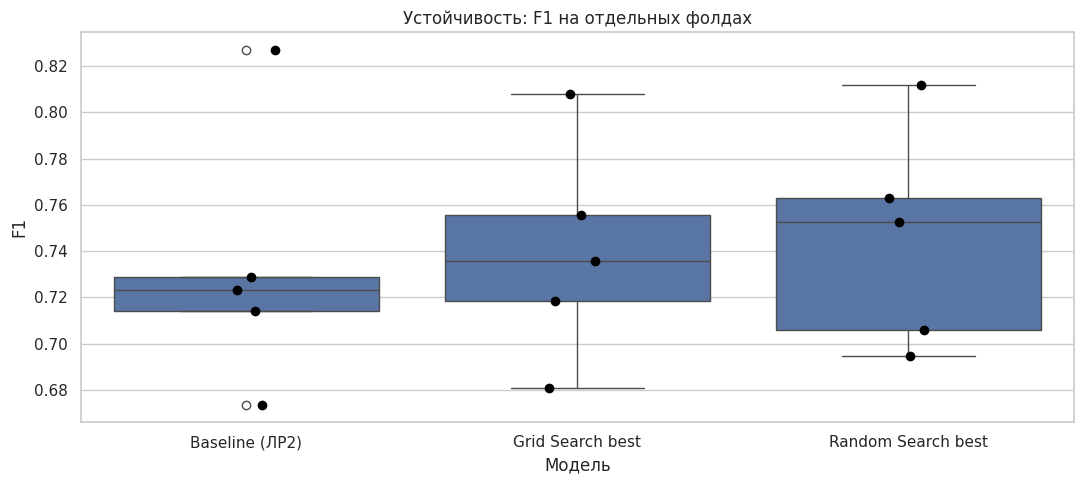

In [16]:
folds_df = pd.DataFrame(fold_scores, index=FOLD_LABELS)
display(folds_df.round(4))
display(folds_df.agg(["mean", "std", "min", "max"]).round(4))
print("Размах (max - min) по фолдам:")
print((folds_df.max() - folds_df.min()).round(4))

long_folds = folds_df.reset_index(names="fold").melt(
    id_vars="fold", var_name="Модель", value_name="F1"
)

fig, ax = plt.subplots(figsize=FIG_SIZE_SINGLE)
sns.boxplot(data=long_folds, x="Модель", y="F1", ax=ax)
sns.stripplot(data=long_folds, x="Модель", y="F1", color="black", size=7, ax=ax)
ax.set_title("Устойчивость: F1 на отдельных фолдах")
plt.tight_layout()
plt.show()